# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнила студентка гр. 3384 Куркина Полина. Вариант №12.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

### Линейные дискретные системы

Линейная дискретная система (ЛДС) с постоянными коэффициентами описывается разностным уравнением:
$$y(n) = \sum_{i=0}^{N-1} b_i\, x(n-i) - \sum_{k=1}^{M-1} a_k\, y(n-k)$$
где $x(n)$ — воздействие, $y(n)$ — реакция, $n$ — дискретное нормированное время (номер отсчёта, $n = nT/T$), $T$ — период дискретизации.

Импульсная характеристика (ИХ) $h(n)$ — это реакция системы на цифровой единичный импульс $u_0(n)$, т.е. на воздействие $x = [1, 0, 0, 0, \dots]$, при нулевых начальных условиях.

Передаточной функцией ЛДС называется отношение $Z$-изображений реакции и воздействия при нулевых начальных условиях; она равна $Z$-изображению ИХ:
$$
H(z) = \frac{Y(z)}{X(z)} = \sum_{n=0}^{\infty} h(n)\, z^{-n}, \qquad Y(z) = H(z)\, X(z).
$$

ПФ общего вида:
$$
H(z) = \frac{\sum_{i=0}^{N-1} b_i z^{-i}}{1 + \sum_{k=1}^{M-1} a_k z^{-k}}, \qquad
$$

Для рекурсивного звена 2-го порядка:
$$
H(z) = \frac{b_0 + b_1 z^{-1} + b_2 z^{-2}}{1 + a_1 z^{-1} + a_2 z^{-2}}, \qquad
y(n) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2) - a_1 y(n-1) - a_2 y(n-2),
$$
при нулевых начальных условиях $x(n) = y(n) = 0$ для $n < 0$.

Подставив в разностное уравнение $x(n) = u_0(n)$, получаем ИХ. Так как реакция зависит от своих предыдущих значений, ИХ рекурсивного звена имеет бесконечную длину. Для устойчивого звена она затухает, поэтому на практике вычисляют конечное число её отсчётов.

Операция свёртки позволяет по ИХ вычислить реакцию на произвольное воздействие:
$$y(n) = \sum_{m=0}^{n} h(m)\, x(n-m).$$
Длина свёртки последовательностей длин $N_x$ и $N_h$ равна $N_x + N_h - 1$.

Нули $z_{0k}$ — корни числителя, полюсы $z_{*k}$ — корни знаменателя передаточной функции (после домножения на $z^2$ это корни квадратных многочленов). Передаточную функцию можно записать в виде:
$$H(z) = b_0 \frac{(1 - z_{01} z^{-1})(1 - z_{02} z^{-1})}{(1 - z_{*1} z^{-1})(1 - z_{*2} z^{-1})}.$$
При вещественных коэффициентах комплексные нули и полюсы образуют комплексно-сопряжённые пары. Связь алгебраической и показательной форм: $z = x + jy = r e^{j\varphi}$, $r = \sqrt{x^2 + y^2}$, $\varphi = \arg z$.

Критерий устойчивости: звено устойчиво тогда и только тогда, когда все полюсы лежат строго внутри единичной окружности ($|z_{*k}| < 1$). Это эквивалентно условию $\sum_{n=0}^{\infty} |h(n)| < \infty$.

Частотная характеристика — передаточная функция на единичной окружности $z = e^{j\hat{\omega}}$, где $\hat{\omega} = \omega T = 2\pi f / f_s$ — нормированная частота:
$$H(e^{j\hat{\omega}}) = \frac{b_0 + b_1 e^{-j\hat{\omega}} + b_2 e^{-2j\hat{\omega}}}{1 + a_1 e^{-j\hat{\omega}} + a_2 e^{-2j\hat{\omega}}} = A(\hat{\omega})\, e^{j\varphi(\hat{\omega})},$$
$A(\hat{\omega})$ — АЧХ, $\varphi(\hat{\omega})$ — ФЧХ. ЧХ периодична с периодом $2\pi$, а при вещественных коэффициентах АЧХ чётная, ФЧХ нечётная, поэтому основная полоса частот — $\hat{\omega} \in [0, \pi]$, или $f \in [0, f_s/2]$.

АЧХ пропорциональна произведению расстояний от точки $e^{j\hat{\omega}}$ до нулей, делённому на произведение расстояний до полюсов. Поэтому вблизи аргумента полюса АЧХ имеет максимум, вблизи аргумента нуля — минимум. Если нуль лежит на единичной окружности, АЧХ обращается в ноль, а ФЧХ делает скачок на $\pi$.

### Дискретное преобразование Фурье

Дискретное преобразование Фурье (ДПФ) последовательности $x(n)$ длины (периода) $N$ и обратное преобразование (ОДПФ):
$$X(k) = \sum_{n=0}^{N-1} x(n)\, e^{-j\frac{2\pi}{N} nk}, \qquad x(n) = \frac{1}{N}\sum_{k=0}^{N-1} X(k)\, e^{j\frac{2\pi}{N} nk}.$$
Номер $k$ — дискретная нормированная частота. Отсчёту $k$ соответствуют нормированная частота $\hat{\omega}_k = 2\pi k/N$ и абсолютная частота $f_k = k f_s / N$ (шаг по частоте $f_s/N$). ДПФ периодично с периодом $N$, а для вещественной последовательности $X(N-k) = X^*(k)$.

Периодическая последовательность раскладывается в сумму $N$ дискретных комплексных экспонент $e^{j\frac{2\pi}{N}nk}$. Их амплитуды и начальные фазы образуют амплитудный спектр $A(k) = |X(k)|/N$ и фазовый спектр $\varphi(k) = \arg X(k)$. Дискретная гармоника $A \cos(\hat{\omega}_0 n + \varphi_0)$ с $\hat{\omega}_0 = 2\pi k_0 / N$ даёт две спектральные линии высотой $A/2$ при $k = k_0$ и $k = N - k_0$ с фазами $\pm\varphi_0$.

ДПФ конечной последовательности длины $N$ — это $N$ отсчётов её спектра (фурье-изображения) $X(e^{j\hat{\omega}})$, взятых на периоде $[0, 2\pi)$ с шагом $2\pi/N$. Модуль ДПФ конечной последовательности отличается от амплитудного спектра её периодического продолжения множителем $N$.

Восстановление аналогового сигнала по отсчётам ДПФ — интерполяция рядом Фурье: отсчёту $X(k)$ соответствует комплексная экспонента $e^{j\frac{2\pi}{NT} kt}$. Отрицательным частотам $k \in [-N/2;\, -1]$ отвечают коэффициенты $X(N+k)$ (вторая половина ДПФ). Если частоты сигнала не превышают $f_s/2$, восстановление точное.

Равенство Парсеваля (сохранение энергии при ДПФ):
$$\sum_{n=0}^{N-1} |x(n)|^2 = \frac{1}{N}\sum_{k=0}^{N-1} |X(k)|^2.$$


## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.


## Часть 1

1. Вычислить импульсную характеристику длины $N_1$ по заданной передаточной функции с коэффициентами $b_i, a_k$ и построить её график. Записать аналитическую формулу импульсной характеристики рекурсивного звена 2-го порядка с учетом нулевых начальных условий. Пояснить, чему в действительности равна длина импульсной характеристики.

2. Вычислить реакцию $y_1(n)$ по формуле свёртки. В качестве воздействия $x(n)$ длины $N_2$ выбрать дискретный прямоугольный импульс:
$$
x(n) = \begin{cases}
1, & 0 \leqslant n < int(N_2/2) \\
0, & int(N_2/2) \leqslant n \leqslant N_2 - 1
\end{cases}
$$
где функция $int(t)$ – округление до ближайшего целого. Вывести графики воздействия и реакции. Пояснить:<br>
&nbsp;&nbsp;&nbsp;&nbsp;a. чему равна длина импульса $x$;<br>
&nbsp;&nbsp;&nbsp;&nbsp;b. чему равна длина свёртки аналитически и по графику;<br>
&nbsp;&nbsp;&nbsp;&nbsp;c. почему её ограничивают до длины воздействия.

3. Вычислить реакцию $y_2(n)$ по разностному уравнению. Задать воздействие $x(n)$ из п. 2. Вывести графики воздействия и реакции. Сравнить графики реакций $y_1(n)$ и $y_2(n)$. Записать разностное уравнение рекурсивного звена 2-го порядка с заданными коэффициентами. Пояснить, чему равны длины воздействия и реакции.

4. Вычислить нули и полюсы передаточной функции. нули и полюсы в алгебраической и показательной формах и пояснить связь между ними. Выразить значение аргумента полюса и нуля относительно $\pi$. Представить передаточную функцию в виде произведения простейших множителей с нулями и полюсами в показательной форме.

5. Изобразить карту нулей и полюсов. Пояснить:<br>
&nbsp;&nbsp;&nbsp;&nbsp;a. является ли рекурсивное звено устойчивым;<br>
&nbsp;&nbsp;&nbsp;&nbsp;b. совпадают ли значения нулей и полюсов с вычисленными в п. 4.

6. Вычислить амплитудно-частотную (АЧХ) и фазочастотную (ФЧХ) характеристики в шкале нормированных частот $\hat{\omega}$ и вывести их графики. Пояснить:<br>
&nbsp;&nbsp;&nbsp;&nbsp;a. чему равны границы основной полосы частот;<br>
&nbsp;&nbsp;&nbsp;&nbsp;b. соответствие между картой нулей и полюсов и видом АЧХ;<br>
&nbsp;&nbsp;&nbsp;&nbsp;c. какому значению АЧХ соответствует скачок на $\pi$, если он имеется;<br>
&nbsp;&nbsp;&nbsp;&nbsp;d. какие частотные составляющие воздействия, низкие или высокие, оказались преимущественно подавленными в реакции.

7. Вычислить АЧХ и ФЧХ в шкале частот $f$ (Гц) при заданной частоте дискретизации $f_s$ и вывести их графики. Пояснить:<br>
&nbsp;&nbsp;&nbsp;&nbsp;a. чему равны границы основной полосы частот;<br>
&nbsp;&nbsp;&nbsp;&nbsp;b. соответствие частотами $\hat{\omega}$ и $f$.

## Часть 2

1. Вывести графики последовательности $x(n)$ на периоде $N$ в шкале дискретного и дискретного нормированного времени:
$$
x(nT) = A_1 \cos(2\pi f_1 nT + \pi/4) + A_2 \cos(2\pi f_2 nT + \pi/8)
$$

2. Вычислить ОДПФ от ДПФ последовательности $x(n)$ и вывести график полученной последовательности в шкале дискретного нормированного времени.

3. Вычислить амплитудный и фазовый спектры последовательности $x(n)$ и вывести их графики в шкалах дискретных нормированных и абсолютных частот. Пояснить:<br>
&nbsp;&nbsp;&nbsp;&nbsp;a. связь дискретного нормированного времени с дискретным временем;<br>
&nbsp;&nbsp;&nbsp;&nbsp;b. связь частоты $f$ (Гц) с дискретной нормированной частотой;<br>
&nbsp;&nbsp;&nbsp;&nbsp;c. вид амплитудного и фазового спектров.

4. Вычислить ДПФ конечной последовательности $x(n)$ длины $N$. Вывести графики в шкале дискретных нормированных частот модуля ДПФ конечной последовательности и амплитудного спектра периодической последовательности. Пояснить связь модуля ДПФ конечной последовательности с амплитудным спектром периодической последовательности.

5. Восстановить периодический аналоговый сигнал $x(t)$ по отсчётам ДПФ $X(k)$ периодической последовательности $x(n)$. Для вычисления значений сигнала $x(t)$ использовать формулу:
$$
x(t) = \frac{1}{N} \sum_{k=-N/2}^{N/2-1} X_a(k) \exp\left(j \frac{2\pi}{NT} kt\right),
$$
где отсчёты $X_a(k)$ связаны с отсчётами ДПФ $X(k)$ соотношением:
$$
X_a(k) = \begin{cases} X(N+k), & -N/2 \leqslant k \leqslant -1 \\ X(k), & 0 \leqslant k \leqslant N/2 - 1 \end{cases}
$$
задавая значения времени $t$ на интервале $t \in [0; (N-1)T]$ с шагом $\Delta t = 0.25T$. Вывести графики:<br>
&nbsp;&nbsp;&nbsp;&nbsp;a. периодической последовательности $x(n)$ и модуля её ДПФ;<br>
&nbsp;&nbsp;&nbsp;&nbsp;b. восстановленного аналогового сигнала $x(t)$ и его амплитудного спектра;<br>
&nbsp;&nbsp;&nbsp;&nbsp;c. исходного аналогового сигнала $x(t) = x(nT)|_{nT = t}$.

6. Исходя из результатов п. 5, объяснить:<br>
&nbsp;&nbsp;&nbsp;&nbsp;a. связь модуля ДПФ последовательности со спектром аналогового сигнала;<br>
&nbsp;&nbsp;&nbsp;&nbsp;b. результат визуального сравнения восстановленного и исходного сигналов.

7. Проверить равенство Парсеваля. Пояснить его смысл.


## Выполнение работы

## Часть 1

### Расчёт параметров для варианта $N_{var} = 12$

**Коэффициенты числителя:**
* $b_0 = 0.5 + 0.02 \cdot 12 = 0.74$
* $b_1 = 0.74 \cdot (-1)^{12+1} \cdot (0.9822 + 0.0178 \cdot 12) = -0.884892$
* $b_2 = 0.74 \cdot (0.8 + 0.2 \cdot (12 \bmod 5)) = 0.888$

**Коэффициенты знаменателя:**
* $a_0 = 1$
* $a_1 = (-1)^{12} \cdot (0.7778 + 0.025 \cdot 12) = 1.0778$
* $a_2 = 0.64 + 0.006 \cdot 12 = 0.712$

**Длины и частота дискретизации:**
* $N_1 = 12 \bmod 10 + 20 = 22$
* $N_2 = 12 \bmod 10 + 30 = 32$
* $f_s = 1000 \cdot 12 = 12000 \ \text{Hz}$

Таким образом, передаточная функция имеет вид:
$$
H(z) = \frac{0.74 - 0.884892 z^{-1} + 0.888 z^{-2}}{1 + 1.0778 z^{-1} + 0.712 z^{-2}}
$$

In [1]:
import math
import cmath
import numpy as np
from matplotlib import pyplot as plt

# Параметры варианта
Nvar = 12
b0 = 0.5 + 0.02 * Nvar
b1 = b0 * (-1)**(Nvar + 1) * (0.9822 + 0.0178 * Nvar)
b2 = b0 * (0.8 + 0.2 * (Nvar % 5))
a0 = 1.0
a1 = (-1)**Nvar * (0.7778 + 0.025 * Nvar)
a2 = 0.64 + 0.006 * Nvar
N1 = Nvar % 10 + 20
N2 = Nvar % 10 + 30
fs = 1000 * Nvar

b = [b0, b1, b2]
a = [a0, a1, a2]
print(f"b = {[round(v, 6) for v in b]}, a = {[round(v, 6) for v in a]}, N1 = {N1}, N2 = {N2}, fs = {fs}")

b = [0.74, -0.884892, 0.888], a = [1.0, 1.0778, 0.712], N1 = 22, N2 = 32, fs = 12000


### п.1

Вычисление импульсной характеристики как реакции на цифровой единичный импульс по рекуррентной формуле (разностному уравнению):

h(n) = [0.74, -1.6825, 2.1745, -1.1457, -0.3134, 1.1535, -1.0201, 0.2782, 0.4265, -0.6577, 0.4053, 0.0315, -0.3225, 0.3252, -0.1208, -0.1013, 0.1952, -0.1383, 0.01, 0.0876, -0.1016, 0.0471]


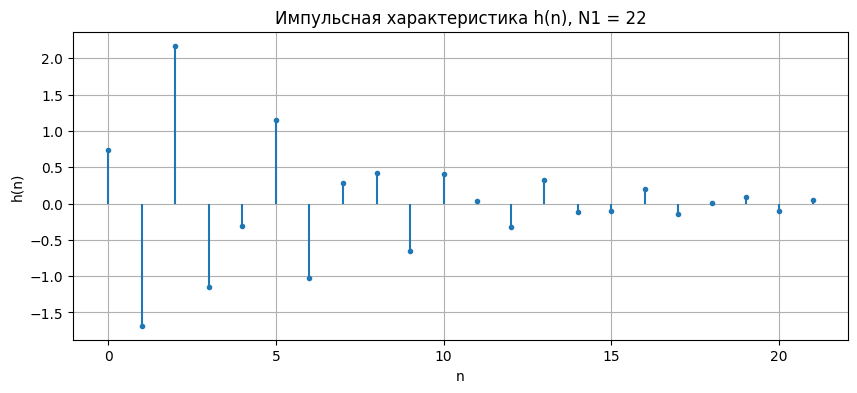

In [2]:
def calc_y(b, a, x):
    """Реакция звена 2-го порядка по разностному уравнению
    y(n) = (b0 x(n) + b1 x(n-1) + b2 x(n-2) - a1 y(n-1) - a2 y(n-2)) / a0
    при нулевых начальных условиях."""
    N = len(x)
    y = [0.0] * N
    for n in range(N):
        xn  = x[n]   if 0 <= n     else 0.0
        xn1 = x[n-1] if 0 <= n - 1 else 0.0
        xn2 = x[n-2] if 0 <= n - 2 else 0.0
        yn1 = y[n-1] if 0 <= n - 1 else 0.0
        yn2 = y[n-2] if 0 <= n - 2 else 0.0
        y[n] = (b[0]*xn + b[1]*xn1 + b[2]*xn2 - a[1]*yn1 - a[2]*yn2) / a[0]
    return y

u0 = [0.0] * N1
u0[0] = 1.0

h = calc_y(b, a, u0)
print("h(n) =", [round(v, 4) for v in h])

plt.figure(figsize=(10, 4))
plt.stem(range(N1), h, basefmt=" ", markerfmt=".")
plt.title(f"Импульсная характеристика h(n), N1 = {N1}")
plt.xlabel("n"); plt.ylabel("h(n)")
plt.grid(True)
plt.show()

Подставив $x(n) = u_0(n)$ в разностное уравнение, получаем формулу для вычисления ИХ:
$$
h(n) = b_0 u_0(n) + b_1 u_0(n-1) + b_2 u_0(n-2) - a_1 h(n-1) - a_2 h(n-2), \qquad h(n) = 0 \text{ for } n < 0.
$$

Первые значения:

$$h(0) = b_0 = 0.74$$

$$h(1) = b_1 - a_1 h(0) = -0.884892 - 1.0778 \cdot 0.74 \approx -1.6825$$

$$h(2) = b_2 - a_1 h(1) - a_2 h(0) = 0.888 + 1.0778 \cdot 1.6825 - 0.712 \cdot 0.74 \approx 2.1745$$

Для $n \geqslant 3$ входной импульс равен нулю, и остаётся только рекурсия:

$$h(n) = -1.0778 \cdot h(n-1) - 0.712 \cdot h(n-2), \qquad n \geqslant 3.$$

**Аналитическая формула.**

По табличной паре $Z$-преобразования
$$
g(n) = r_*^{\,n}\frac{\sin\big((n+1)\varphi_*\big)}{\sin\varphi_*}\,u_1(n) \;\longleftrightarrow\; \frac{1}{1 + a_1 z^{-1} + a_2 z^{-2}}, \qquad a_1 = -2r_*\cos\varphi_*,\quad a_2 = r_*^2, $$ <br>
откуда $r_* = \sqrt{a_2} \approx 0.8438$, $\varphi_* = \arccos\left(-a_1/(2r_*)\right) \approx 2.2635 \approx 0.7205\pi$ ($r_* e^{\pm j\varphi_*}$ — полюсы).
<br><br>
Так как $H(z) = (b_0 + b_1 z^{-1} + b_2 z^{-2}) \cdot \dfrac{1}{1 + a_1 z^{-1} + a_2 z^{-2}}$, <br>
по теореме о задержке $Z\{g(n-m)\} = z^{-m}G(z)$,<br>
где $G(z) = 1/(1 + a_1 z^{-1} + a_2 z^{-2})$ <br>
получаем
$$
h(n) = b_0\,g(n) + b_1\,g(n-1) + b_2\,g(n-2) = 0.74\,g(n) - 0.884892\,g(n-1) + 0.888\,g(n-2).
$$




In [3]:
# проверка: ИХ по разностному уравнению и по аналитической формуле
r_p   = math.sqrt(a2)
phi_p = math.acos(-a1 / (2 * r_p))
h0 = lambda n: r_p**n * math.sin((n + 1) * phi_p) / math.sin(phi_p) if n >= 0 else 0.0
h_formula = [b0*h0(n) + b1*h0(n-1) + b2*h0(n-2) for n in range(N1)]
print(f"r = {r_p:.4f}, phi = {phi_p:.4f} = {phi_p/math.pi:.4f}*pi")
print("max |h - h_formula| =", max(abs(u - v) for u, v in zip(h, h_formula)))

r = 0.8438, phi = 2.2635 = 0.7205*pi
max |h - h_formula| = 1.7208456881689926e-15


Значения совпадают с точностью до ошибок округления.

В действительности ИХ имеет бесконечную длину: каждое следующее значение — взвешенная сумма двух предыдущих, поэтому $h(n)$ никогда не обращается в ноль, а лишь затухает. Длина $N_1 = 22$ — это число вычисленных отсчётов; к $n = 21$ огибающая уменьшается до $0.8438^{21} \approx 0.03$, поэтому отброшенный «хвост» мал. Аргумент полюсов $\varphi \approx 0.72\pi$ близок к $\pi$, поэтому ИХ быстро колеблется (период $2\pi/\varphi \approx 2.8$ отсчёта) и её знак почти чередуется.

### п.2

Воздействие — прямоугольный импульс. Реакция $y_1$ вычисляется сверткой воздействия с ИХ:

Число единиц в импульсе: 16
Длина полной свертки: 53
Последний ненулевой отсчёт свертки: n = 36


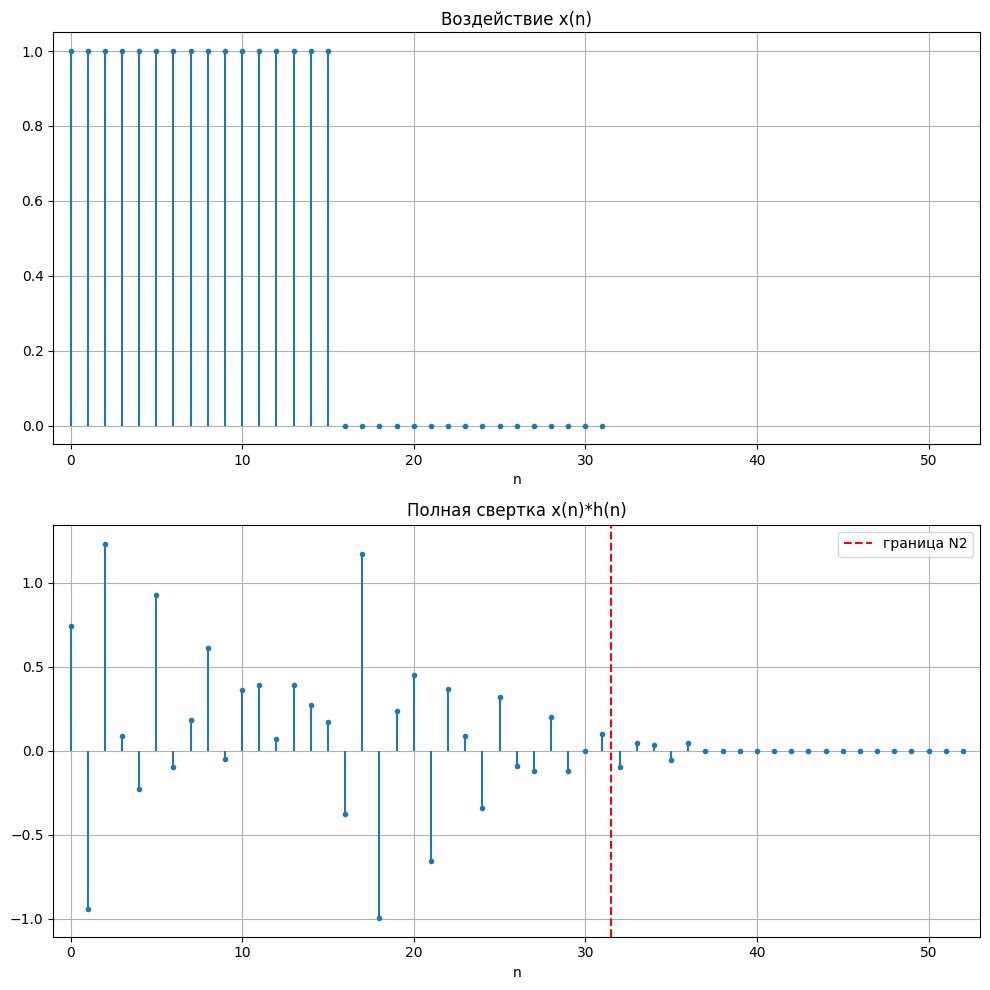

In [4]:
def calc_x():
    """Прямоугольный импульс длины N2: первые int(N2/2) отсчётов равны 1"""
    L = int(N2 / 2 + 0.5)
    return [1.0 if n < L else 0.0 for n in range(N2)]

def convolution(a, b):
    Na, Nb = len(a), len(b)
    N = Na + Nb - 1
    y = [0.0] * N
    for n in range(N):
        for k in range(Na):
            if 0 <= n - k < Nb:
                y[n] += a[k] * b[n - k]
    return y

x = calc_x()
y_full = convolution(x, h)
y1 = y_full[:N2]

print("Число единиц в импульсе:", int(sum(x)))
print("Длина полной свертки:", len(y_full))
print("Последний ненулевой отсчёт свертки: n =", max(n for n in range(len(y_full)) if abs(y_full[n]) > 1e-12))

fig, axs = plt.subplots(2, figsize=(10, 10))
axs[0].stem(range(N2), x, basefmt=" ", markerfmt=".");                  axs[0].set_title("Воздействие x(n)")
axs[1].stem(range(len(y_full)), y_full, basefmt=" ", markerfmt=".");    axs[1].set_title("Полная свертка x(n)*h(n)")
axs[1].axvline(N2 - 0.5, color="r", ls="--", label="граница N2");       axs[1].legend()

for ax in axs:
    ax.set_xlim(-1, len(y_full)); ax.set_xlabel("n"); ax.grid(True)
plt.tight_layout(); plt.show()

a. Длина последовательности $x$ — $N_2 = 32$ отсчёта. Длина самого импульса (без нулей) — $int(32/2) = 16$ отсчётов, $n = 0, \dots, 15$.

b. Аналитически длина свертки равна $N_2 + N_1 - 1 = 32 + 22 - 1 = 53$. По графику ненулевые отсчёты занимают $n = 0, \dots, 36$, т.е. $16 + 22 - 1 = 37$ отсчётов (свертка импульса из 16 единиц с ИХ из 22 отсчётов), дальше идут нули, порождённые нулевым «хвостом» воздействия.

c. Реакцию ограничивают длиной воздействия, чтобы её было удобно сравнивать с $y_2(n)$, рассчитанной по разностному уравнению, у которой столько же отсчётов. Кроме того, отсчёты свёртки при $n \geqslant N_1$ искажены усечением $h(n)$ до $N_1$ отсчётов.

### п.3

Разностное уравнение рекурсивного звена 2-го порядка с заданными коэффициентами:
$$
y(n) = 0.74\,x(n) - 0.884892\,x(n-1) + 0.888\,x(n-2) - 1.0778\,y(n-1) - 0.712\,y(n-2)
$$

Вычисление реакции на прямоугольный импульс по разностному уравнению (используется функция из первого пункта):

Длина воздействия: 32  длина реакции: 32


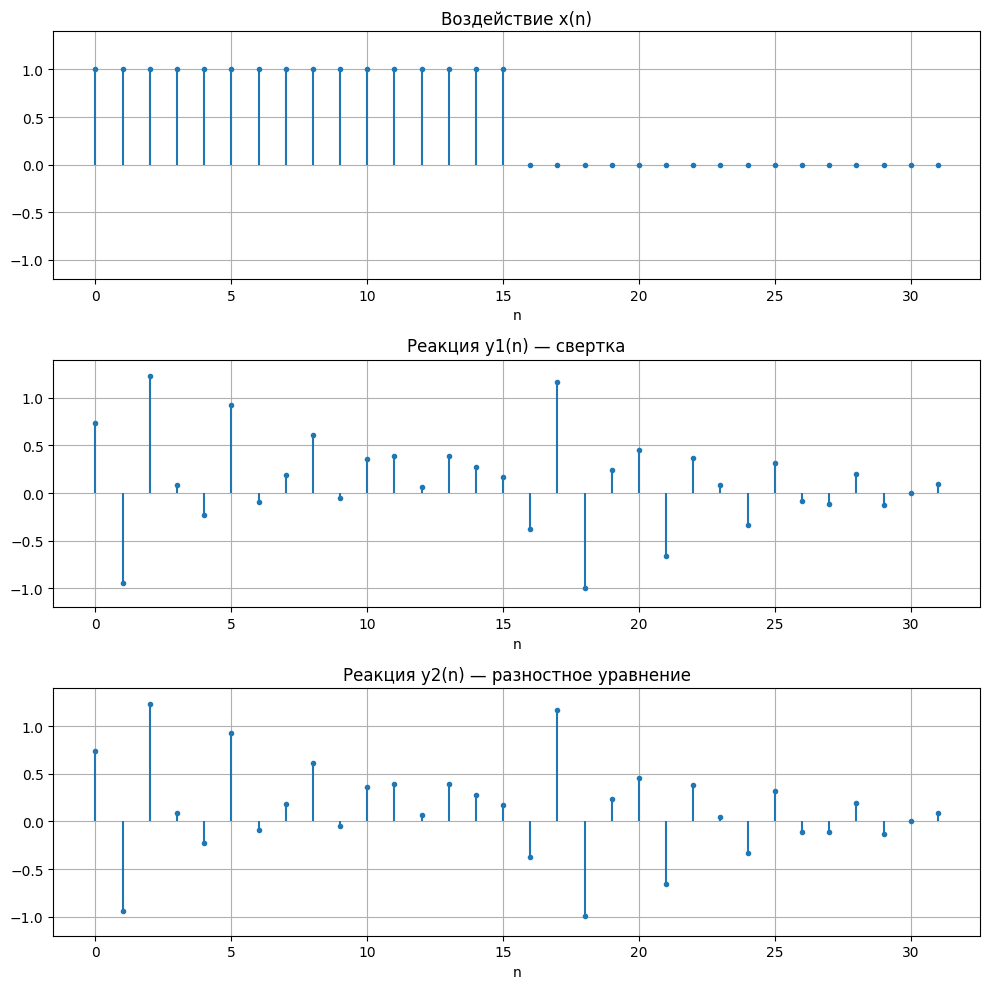

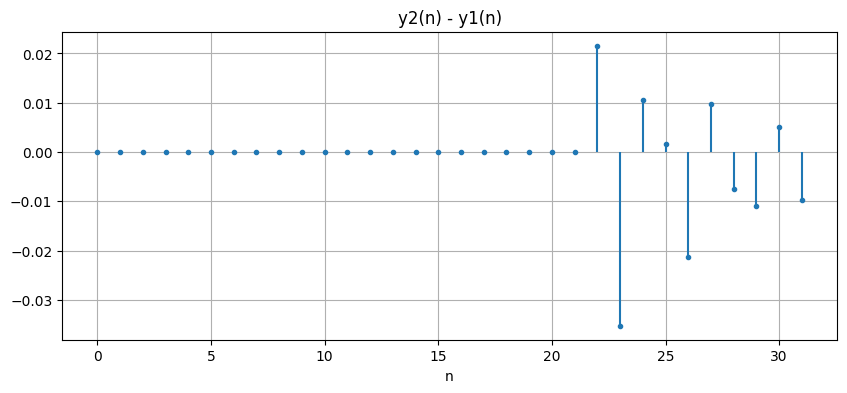

max |y2 - y1| при n < N1: 3.3306690738754696e-16
max |y2 - y1| при n >= N1: 0.03521844673442032


In [5]:
y2 = calc_y(b, a, x)
print("Длина воздействия:", len(x), " длина реакции:", len(y2))

fig, axs = plt.subplots(3, figsize=(10, 10))
axs[0].stem(range(N2), x,  basefmt=" ", markerfmt="."); axs[0].set_title("Воздействие x(n)")
axs[1].stem(range(N2), y1, basefmt=" ", markerfmt="."); axs[1].set_title("Реакция y1(n) — свертка")
axs[2].stem(range(N2), y2, basefmt=" ", markerfmt="."); axs[2].set_title("Реакция y2(n) — разностное уравнение")
for ax in axs:
    ax.set_xlabel("n"); ax.grid(True); ax.set_ylim(-1.2, 1.4)
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 4))
plt.stem(range(N2), [y2[n] - y1[n] for n in range(N2)], basefmt=" ", markerfmt=".")
plt.title("y2(n) - y1(n)"); plt.xlabel("n"); plt.grid(True)
plt.show()

print("max |y2 - y1| при n < N1:", max(abs(y2[n] - y1[n]) for n in range(N1)))
print("max |y2 - y1| при n >= N1:", max(abs(y2[n] - y1[n]) for n in range(N1, N2)))

Длина воздействия — 32 отсчёта (16 без нулей), длина вычисленной реакции — тоже 32 отсчёта: на каждый входной отсчёт вычисляется один выходной. Истинная реакция рекурсивного звена бесконечна.

Графики $y_1(n)$ и $y_2(n)$ визуально совпадают. При $n < N_1 = 22$ они совпадают точно: в свертке используются только вычисленные отсчёты ИХ. При $n \geqslant 22$ появляется расхождение до $\approx 0.035$: свертка выполнялась с ИХ, усечённой до 22 отсчётов, т.е. влияние входных отсчётов старше 22 тактов не учитывается. Рекуррентная формула через $y(n-1)$, $y(n-2)$ «помнит» всю бесконечную ИХ, её единственные ошибки — ошибки округления. Расхождение мало, т.к. к этому моменту ИХ почти затухла.

По виду реакция мало похожа на прямоугольный импульс: звено подавляет низкие частоты (см. п. 6), поэтому наибольшие отклики приходятся на фронты импульса ($n = 0$ и $n = 16$) в виде быстрых затухающих колебаний, а на «плоской» части импульса реакция стремится к малому уровню $A(0) \approx 0.27$.

### п.4

Числитель и знаменатель домножаются на $z^2$:
$$
H(z) = \frac{0.74 z^2 - 0.884892 z + 0.888}{z^2 + 1.0778 z + 0.712}.
$$
Нули и полюсы — корни этих квадратных многочленов:

In [6]:
def solve_eq(A, B, C):
    """Корни квадратного уравнения A z^2 + B z + C = 0"""
    sqrtD = cmath.sqrt(B*B - 4*A*C)
    return (-B + sqrtD) / (2*A), (-B - sqrtD) / (2*A)

zeros = solve_eq(b0, b1, b2)
poles = solve_eq(a0, a1, a2)

def show(name, zs):
    for i, z in enumerate(zs, 1):
        print(f"{name}{i}: {z.real:+.4f} {z.imag:+.4f}j = "
              f"{abs(z):.4f}*exp({cmath.phase(z):+.4f}j) = "
              f"{abs(z):.4f}*exp({cmath.phase(z)/math.pi:+.4f}j*pi)")

show("нуль  z0_", zeros)
show("полюс z*_", poles)

нуль  z0_1: +0.5979 +0.9179j = 1.0954*exp(+0.9934j) = 1.0954*exp(+0.3162j*pi)
нуль  z0_2: +0.5979 -0.9179j = 1.0954*exp(-0.9934j) = 1.0954*exp(-0.3162j*pi)
полюс z*_1: -0.5389 +0.6493j = 0.8438*exp(+2.2635j) = 0.8438*exp(+0.7205j*pi)
полюс z*_2: -0.5389 -0.6493j = 0.8438*exp(-2.2635j) = 0.8438*exp(-0.7205j*pi)


| | алгебраическая форма | модуль | аргумент, рад | аргумент относительно $\pi$ |
|---|---|---|---|---|
| нули $z_{01,2}$ | $0.5979 \pm j\,0.9179$ | $1.0954$ | $\pm 0.9934$ | $\pm 0.3162\pi$ |
| полюсы $z_{*1,2}$ | $-0.5389 \pm j\,0.6493$ | $0.8438$ | $\pm 2.2635$ | $\pm 0.7205\pi$ |

Связь между алгебраической ($z = x + jy$) и показательной ($z = r e^{j\varphi}$) формами:

$r = \sqrt{x^2 + y^2}$, $\varphi = \mathrm{\mathrm{arctg}}(y, x) \in (-\pi, \pi]$, с учётом квадранта

В обратную сторону: $x = r\cos\varphi$, $y = r\sin\varphi$.

Так как коэффициенты вещественные, нули и полюсы — комплексно-сопряжённые пары: модули одинаковы, аргументы отличаются знаком. Это согласуется с коэффициентами: $|z_*|^2 = a_2 = 0.712$, $|z_0|^2 = b_2/b_0 = 1.2$.

Передаточная функция в виде произведения простейших множителей:
$$
H(z) = 0.74\, \frac{\left(1 - 1.0954 e^{0.3162 j\pi} z^{-1}\right)\left(1 - 1.0954 e^{-0.3162 j\pi} z^{-1}\right)}{\left(1 - 0.8438 e^{0.7205 j\pi} z^{-1}\right)\left(1 - 0.8438 e^{-0.7205 j\pi} z^{-1}\right)}
$$

### п.5

Построение карты нулей и полюсов:

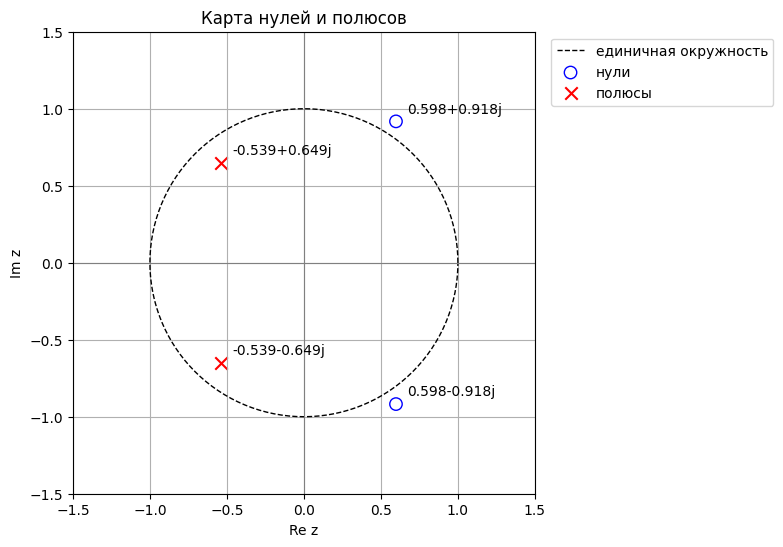

Модули полюсов: [0.8438, 0.8438]


In [7]:
t_circ = [2 * math.pi * k / 256 for k in range(257)]
plt.figure(figsize=(6, 6))
plt.plot([math.cos(t) for t in t_circ], [math.sin(t) for t in t_circ], "k--", lw=1, label="единичная окружность")
plt.scatter([z.real for z in zeros], [z.imag for z in zeros], s=80, marker="o", facecolors="none", edgecolors="blue", label="нули")
plt.scatter([z.real for z in poles], [z.imag for z in poles], s=80, marker="x", color="red", label="полюсы")
for z in zeros + poles:
    plt.annotate(f"{z.real:.3f}{z.imag:+.3f}j", (z.real, z.imag), textcoords="offset points", xytext=(8, 6))
plt.axhline(0, color="gray", lw=0.8); plt.axvline(0, color="gray", lw=0.8)
plt.xlim(-1.5, 1.5); plt.ylim(-1.5, 1.5); plt.gca().set_aspect("equal")
plt.xlabel("Re z"); plt.ylabel("Im z"); plt.title("Карта нулей и полюсов")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1)); plt.grid(True)
plt.show()

print("Модули полюсов:", [round(abs(p), 4) for p in poles])

a. Рекурсивное звено **устойчиво**, так как оба полюса лежат внутри единичной окружности.

b. Положения нулей и полюсов на карте совпадают с вычисленными в п. 4: полюсы $-0.5389 \pm j0.6493$ (под углом $\pm 0.72\pi$), нули $0.5979 \pm j0.9179$ (под углом $\pm 0.32\pi$).

### п.6

Вычисление АЧХ и ФЧХ в основной полосе $\hat{\omega} \in [0, \pi]$ по формуле частотной характеристики:


A(0)  = 0.266,  A(pi) = 3.962
max A = 8.819 при w = 0.730*pi
min A = 0.061 при w = 0.313*pi
Скачки ФЧХ при w/pi = [0.457] величиной (в долях pi): [1.999]


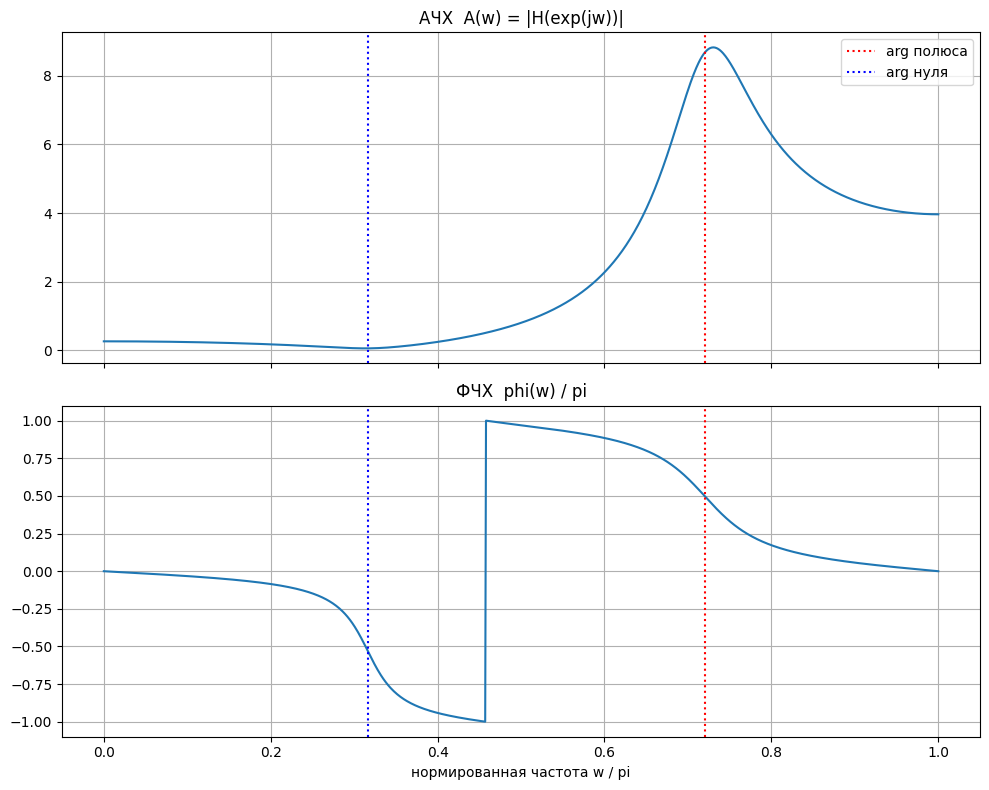

In [8]:
def freq_resp(b, a, w):
    """Частотная характеристика H(e^jw) звена 2-го порядка"""
    z = cmath.exp(1j * w)
    return (b[0] + b[1]/z + b[2]/z**2) / (a[0] + a[1]/z + a[2]/z**2)

M = 1024
w_list   = [math.pi * k / M for k in range(M + 1)]
H_list   = [freq_resp(b, a, w) for w in w_list]
A_list   = [abs(H) for H in H_list]
phi_list = [cmath.phase(H) for H in H_list]

i_max = max(range(len(A_list)), key=lambda i: A_list[i])
i_min = min(range(len(A_list)), key=lambda i: A_list[i])
print(f"A(0)  = {A_list[0]:.3f},  A(pi) = {A_list[-1]:.3f}")
print(f"max A = {A_list[i_max]:.3f} при w = {w_list[i_max]/math.pi:.3f}*pi")
print(f"min A = {A_list[i_min]:.3f} при w = {w_list[i_min]/math.pi:.3f}*pi")
jumps = [i for i in range(M) if abs(phi_list[i+1] - phi_list[i]) > math.pi / 2]
print("Скачки ФЧХ при w/pi =", [round(w_list[i]/math.pi, 3) for i in jumps],
      "величиной (в долях pi):", [round((phi_list[i+1] - phi_list[i])/math.pi, 3) for i in jumps])

w_pi = [w / math.pi for w in w_list]
fig, axs = plt.subplots(2, figsize=(10, 8), sharex=True)
axs[0].plot(w_pi, A_list);                       axs[0].set_title("АЧХ  A(w) = |H(exp(jw))|")
axs[1].plot(w_pi, [p / math.pi for p in phi_list]); axs[1].set_title("ФЧХ  phi(w) / pi")
for ax in axs:
    ax.axvline(cmath.phase(poles[0]) / math.pi, color="r", ls=":", label="arg полюса")
    ax.axvline(cmath.phase(zeros[0]) / math.pi, color="b", ls=":", label="arg нуля")
    ax.grid(True)
axs[0].legend(); axs[1].set_xlabel("нормированная частота w / pi")
plt.tight_layout(); plt.show()

a. Границы основной полосы частот — $\hat{\omega} \in [0, \pi]$: ЧХ периодична с периодом $2\pi$, а при вещественных коэффициентах АЧХ чётная и ФЧХ нечётная, поэтому значения на $[-\pi, 0]$ однозначно определяются значениями на $[0, \pi]$.

b. Максимум АЧХ $A_{\max} \approx 8.82$ при $\hat{\omega} \approx 0.730\pi$ соответствует полюсам ($\arg z_* = 0.7205\pi$): полюсы близки к единичной окружности, и вблизи их аргумента расстояние от точки $e^{j\hat{\omega}}$ до полюса минимально. Минимум АЧХ $A_{\min} \approx 0.061$ при $\hat{\omega} \approx 0.313\pi$ соответствует нулям ($\arg z_0 = 0.3162\pi$); так как нули не лежат на единичной окружности, АЧХ в минимуме не равна нулю. На краях полосы $A(0) \approx 0.27$, $A(\pi) \approx 3.96$.

c. Скачок ФЧХ на $\pi$ соответствует нулевому значению АЧХ (нуль на единичной окружности). Здесь АЧХ в ноль не обращается, поэтому **скачка на $\pi$ нет**. Скачок при $\hat{\omega} \approx 0.46\pi$ имеет величину $2\pi$ и связан только с приведением фазы к главному значению $(-\pi, \pi]$.

d. АЧХ мала на низких частотах и велика на высоких. Поэтому в реакции **преимущественно подавлены низкие частоты** воздействия

### п.7

Вычисление АЧХ и ФЧХ в шкале частот $f$ при частоте дискретизации $f_s = 12000$ Гц, $\hat{\omega} = 2\pi f / f_s$:

Границы основной полосы: [0, 6000] Гц
max A = 8.819 при f = 4383 Гц
min A = 0.061 при f = 1881 Гц


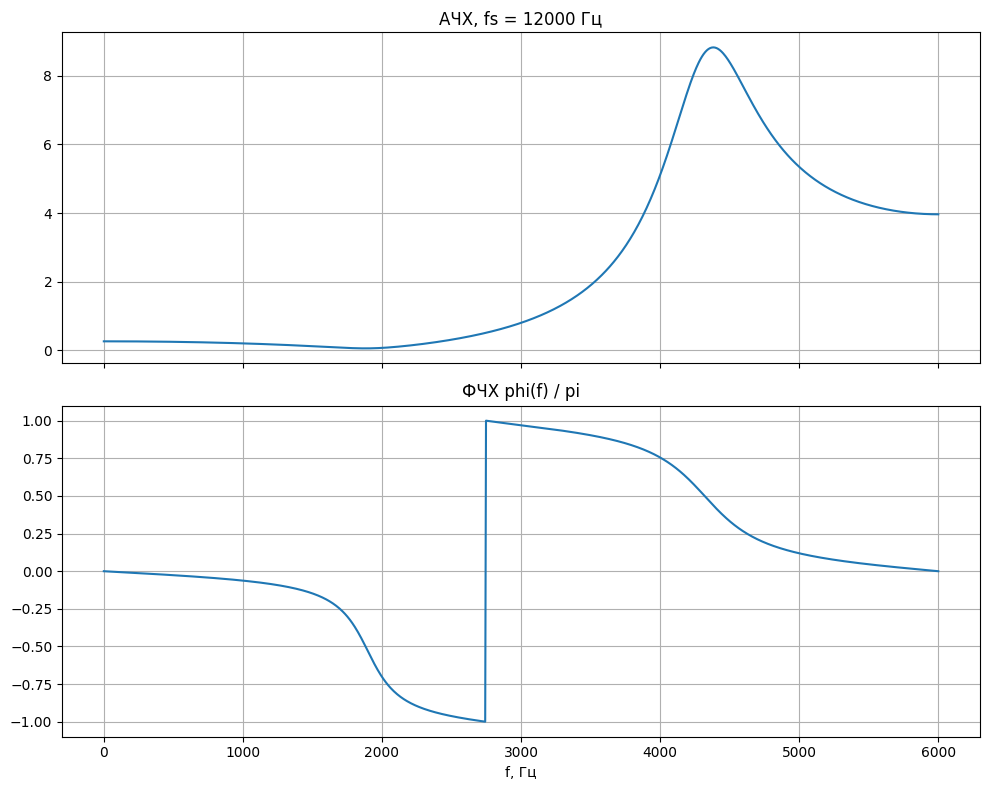

In [9]:
f_list = [w * fs / (2 * math.pi) for w in w_list]

print(f"Границы основной полосы: [0, {fs/2:.0f}] Гц")
print(f"max A = {A_list[i_max]:.3f} при f = {f_list[i_max]:.0f} Гц")
print(f"min A = {A_list[i_min]:.3f} при f = {f_list[i_min]:.0f} Гц")

fig, axs = plt.subplots(2, figsize=(10, 8), sharex=True)
axs[0].plot(f_list, A_list);                           axs[0].set_title(f"АЧХ, fs = {fs} Гц")
axs[1].plot(f_list, [p / math.pi for p in phi_list]); axs[1].set_title("ФЧХ phi(f) / pi")
axs[1].set_xlabel("f, Гц")
for ax in axs:
    ax.grid(True)
plt.tight_layout(); plt.show()

a. Границы основной полосы частот — $[0, f_s/2] = [0, 6000]$ Гц.

b. Связь между нормированной и абсолютной частотой:
$$f = \frac{\hat{\omega} f_s}{2\pi}, \qquad \hat{\omega} = \frac{2\pi f}{f_s}.$$
Графики в шкале $f$ совпадают с графиками в шкале $\hat{\omega}$ с точностью до масштаба оси:

| $\hat{\omega}$ | $0$ | $0.313\pi$ (минимум АЧХ) | $0.730\pi$ (максимум АЧХ) | $\pi$ |
|---|---|---|---|---|
| $f$, Hz | $0$ | $\approx 1880$ | $\approx 4380$ | $6000 = f_s/2$ |

## Часть 2

Вариант 12. Вычисление параметров:

* $N = 64$
* $f_s = 2000 \cdot (12 \bmod 5 + 1) = 2000 \cdot 3 = 6000\ \text{Hz}$
* $T = 1/f_s = 1/6000 \approx 1.667 \cdot 10^{-4}\ \text{s}$
* $A_1 = 1 + 0.01 \cdot 12 = 1.12$, $A_2 = 2A_1 = 2.24$
* $f_1 = f_s/8 = 750\ \text{Hz}$, $f_2 = 1.5 f_1 = 1125\ \text{Hz}$

Нормированные частоты гармоник: $\hat{\omega}_1 = 2\pi f_1 / f_s = \pi/4$, $\hat{\omega}_2 = 2\pi f_2 / f_s = 3\pi/8$, т.е.
$$
x(n) = 1.12 \cos\left(\frac{\pi}{4} n + \frac{\pi}{4}\right) + 2.24 \cos\left(\frac{3\pi}{8} n + \frac{\pi}{8}\right).
$$
На периоде $N = 64$ укладывается ровно $64 \cdot 750/6000 = 8$ периодов первой гармоники и $12$ периодов второй, поэтому последовательность периодична с периодом $N$.

In [10]:
Nvar = 12
N  = 64
fs2 = 2000 * (Nvar % 5 + 1)
T  = 1 / fs2
A1 = 1 + 0.01 * Nvar
A2 = 2 * A1
f1 = fs2 / 8
f2 = 1.5 * f1
print(f"N = {N}, fs = {fs2} Гц, T = {T:.6e} с, A1 = {A1}, A2 = {A2}, f1 = {f1} Гц, f2 = {f2} Гц")

N = 64, fs = 6000 Гц, T = 1.666667e-04 с, A1 = 1.12, A2 = 2.24, f1 = 750.0 Гц, f2 = 1125.0 Гц


### п.1

Вычисление последовательности $x(nT)$ и её графики в шкале дискретного времени $nT$ и дискретного нормированного времени $n$:

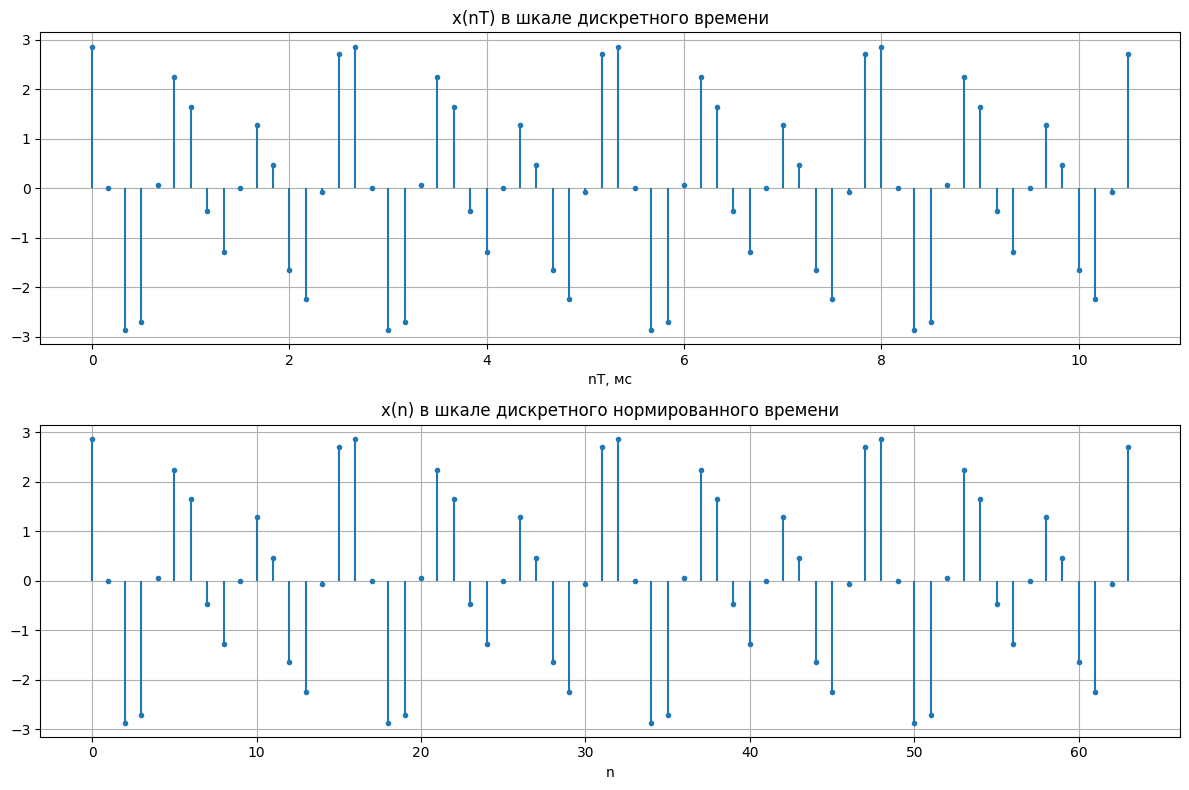

In [11]:
def calc_xa(t):
    """Аналоговый сигнал; при t = nT даёт отсчёты последовательности x(nT)"""
    return A1 * math.cos(2*math.pi*f1*t + math.pi/4) + A2 * math.cos(2*math.pi*f2*t + math.pi/8)

ns = list(range(N))
xs = [calc_xa(n * T) for n in ns]

fig, axs = plt.subplots(2, figsize=(12, 8))
axs[0].stem([n * T * 1000 for n in ns], xs, basefmt=" ", markerfmt=".")
axs[0].set_title("x(nT) в шкале дискретного времени"); axs[0].set_xlabel("nT, мс")
axs[1].stem(ns, xs, basefmt=" ", markerfmt=".")
axs[1].set_title("x(n) в шкале дискретного нормированного времени"); axs[1].set_xlabel("n")
for ax in axs: ax.grid(True)
plt.tight_layout(); plt.show()

### п.2

Вычисление ДПФ последовательности $x(n)$ и ОДПФ от полученного ДПФ:

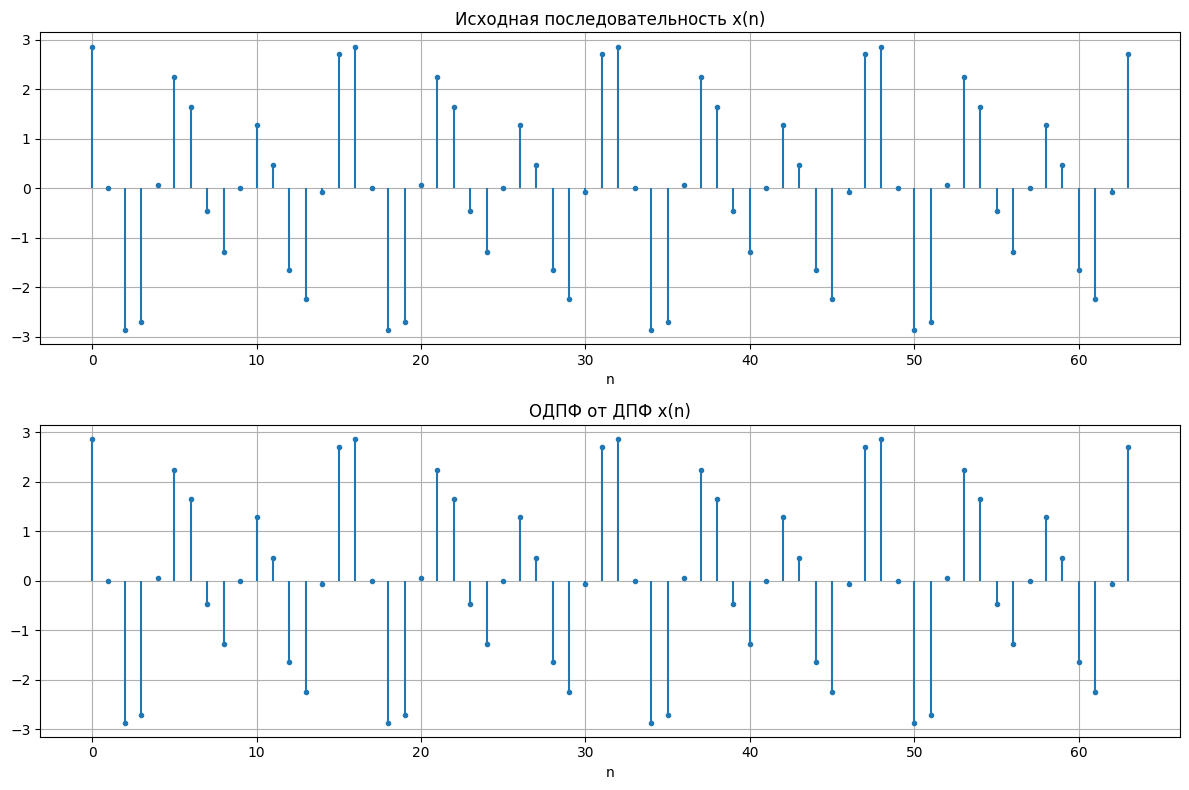

max |x2(n) - x(n)| = 4.4356211981537336e-14
max |Im x2(n)|     = 2.1590373121377873e-14


In [12]:
def dft(x):
    N = len(x)
    X = [0j] * N
    for k in range(N):
        for n in range(N):
            X[k] += x[n] * cmath.exp(-1j * 2 * math.pi / N * n * k)
    return X

def idft(X):
    N = len(X)
    x = [0j] * N
    for n in range(N):
        for k in range(N):
            x[n] += X[k] * cmath.exp(1j * 2 * math.pi / N * n * k)
        x[n] /= N
    return x

X   = dft(xs)
xs2 = idft(X)

fig, axs = plt.subplots(2, figsize=(12, 8))
axs[0].stem(ns, xs, basefmt=" ", markerfmt=".");                   axs[0].set_title("Исходная последовательность x(n)")
axs[1].stem(ns, [v.real for v in xs2], basefmt=" ", markerfmt="."); axs[1].set_title("ОДПФ от ДПФ x(n)")
for ax in axs: ax.set_xlabel("n"); ax.grid(True)
plt.tight_layout(); plt.show()

print("max |x2(n) - x(n)| =", max(abs(xs2[n] - xs[n]) for n in ns))
print("max |Im x2(n)|     =", max(abs(v.imag) for v in xs2))

ОДПФ от ДПФ восстанавливает исходную последовательность с точностью до ошибок машинного округления.

### п.3

Амплитудный $A(k) = |X(k)|/N$ и фазовый $\varphi(k) = \arg X(k)$ спектры в шкалах дискретной нормированной частоты $\hat{\omega}_k = 2\pi k / N$ и абсолютной частоты $f_k = k f_s / N$ (фаза показана только в точках с ненулевой амплитудой — в остальных точках $X(k) \approx 0$ и её значение определяется ошибками округления):

k =  8: w = 0.2500*pi, f =    750 Гц, A = 0.5600, phi = +0.2500*pi
k = 12: w = 0.3750*pi, f =   1125 Гц, A = 1.1200, phi = +0.1250*pi
k = 52: w = 1.6250*pi, f =   4875 Гц, A = 1.1200, phi = -0.1250*pi
k = 56: w = 1.7500*pi, f =   5250 Гц, A = 0.5600, phi = -0.2500*pi


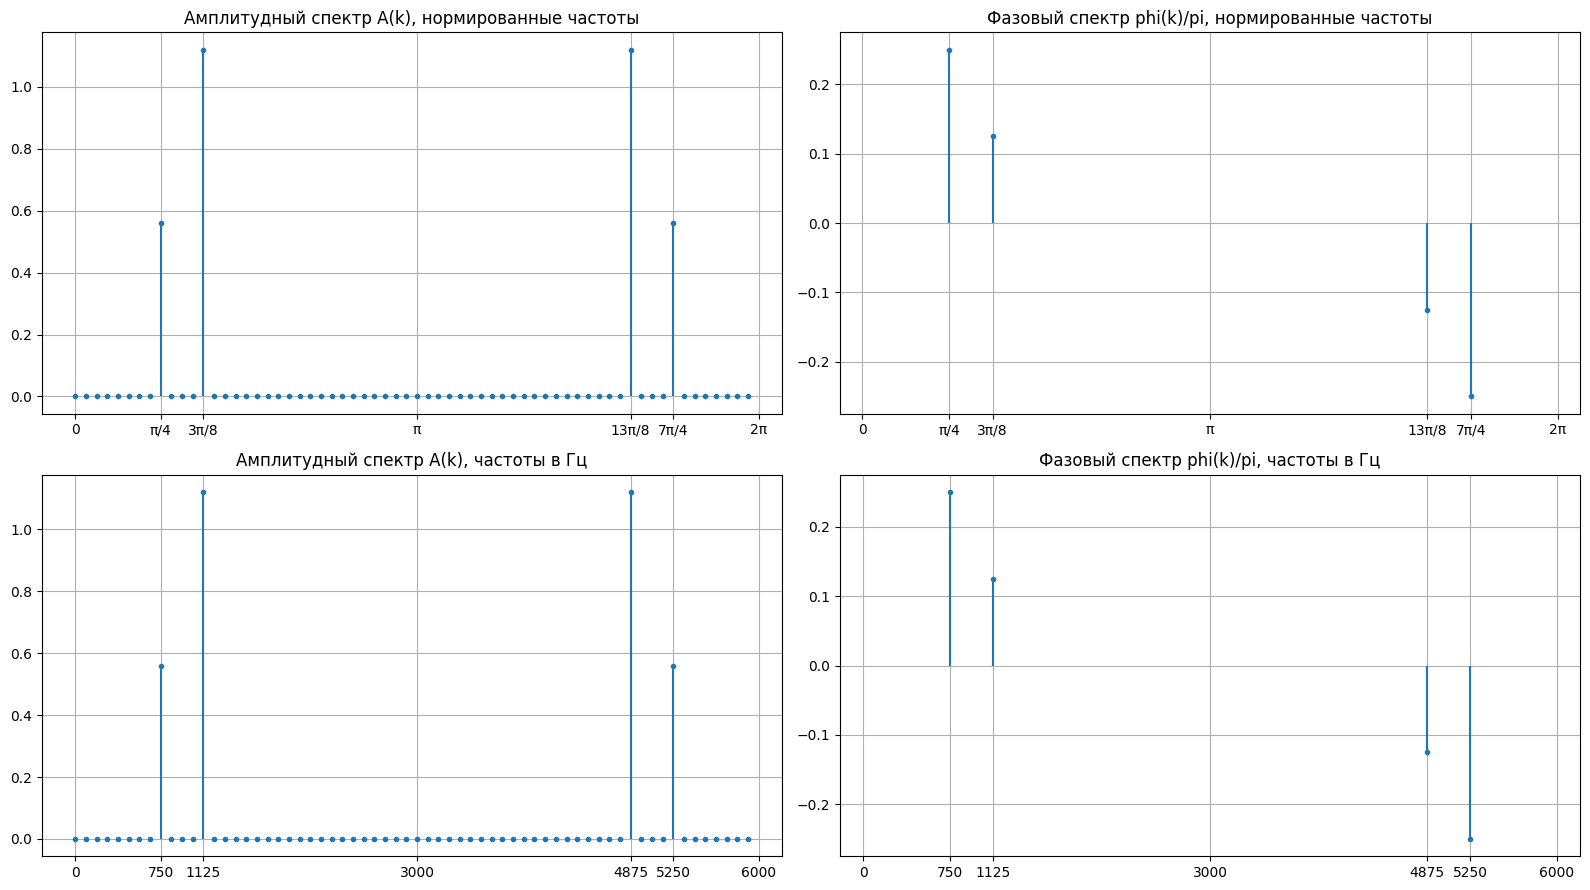

In [13]:
Ak   = [abs(v) / N for v in X]
phik = [cmath.phase(v) if abs(v) > 1e-9 else 0.0 for v in X]
nz   = [k for k in ns if abs(X[k]) > 1e-9]

w_k = [2 * math.pi * k / N for k in ns]
f_k = [k * fs2 / N for k in ns]

for k in nz:
    print(f"k = {k:2d}: w = {k/N*2:.4f}*pi, f = {f_k[k]:6.0f} Гц, A = {Ak[k]:.4f}, phi = {phik[k]/math.pi:+.4f}*pi")

pi = math.pi
w_ticks  = [0, pi/4, 3*pi/8, pi, 13*pi/8, 7*pi/4, 2*pi]
w_labels = ["0", "π/4", "3π/8", "π", "13π/8", "7π/4", "2π"]
f_ticks  = [0, f1, f2, fs2/2, fs2 - f2, fs2 - f1, fs2]

fig, axs = plt.subplots(2, 2, figsize=(16, 9))
axs[0,0].stem(w_k, Ak, basefmt=" ", markerfmt=".");  axs[0,0].set_xticks(w_ticks, w_labels)
axs[0,0].set_title("Амплитудный спектр A(k), нормированные частоты")
axs[0,1].stem([w_k[k] for k in nz], [phik[k]/pi for k in nz], basefmt=" ", markerfmt=".");  axs[0,1].set_xticks(w_ticks, w_labels)
axs[0,1].set_xlim(-0.2, 2*pi + 0.2); axs[0,1].set_title("Фазовый спектр phi(k)/pi, нормированные частоты")
axs[1,0].stem(f_k, Ak, basefmt=" ", markerfmt=".");  axs[1,0].set_xticks(f_ticks)
axs[1,0].set_title("Амплитудный спектр A(k), частоты в Гц")
axs[1,1].stem([f_k[k] for k in nz], [phik[k]/pi for k in nz], basefmt=" ", markerfmt=".");  axs[1,1].set_xticks(f_ticks)
axs[1,1].set_xlim(-200, fs2 + 200); axs[1,1].set_title("Фазовый спектр phi(k)/pi, частоты в Гц")
for ax in axs.flat: ax.grid(True)
plt.tight_layout(); plt.show()

a. Связь дискретного нормированного времени с дискретным временем: $n = nT / T$, т.е. время измеряется в периодах дискретизации. Отсчётам $n = 0, 1, \dots, N-1 = 63$ соответствуют моменты $nT = 0,\ T,\ \dots,\ 63T \approx 10.5$ мс.

b. Связь частоты $f$ (Гц) с дискретной нормированной частотой: $\hat{\omega} = 2\pi f / f_s$, $f = \hat{\omega} f_s / (2\pi)$. Для отсчётов ДПФ $\hat{\omega}_k = 2\pi k / N$, $f_k = k f_s / N$, шаг по частоте $f_s / N = 93.75$ Гц. Частоты гармоник $f_1 = 750$ Гц и $f_2 = 1125$ Гц попадают точно на отсчёты $k = 8$ ($\hat{\omega} = \pi/4$) и $k = 12$ ($\hat{\omega} = 3\pi/8$).

c. Каждый косинус раскладывается на две комплексные экспоненты:
$$
\begin{aligned}
x(n) & = 1.12 \cos\left(\frac{\pi}{4} n + \frac{\pi}{4}\right) + 2.24 \cos\left(\frac{3\pi}{8} n + \frac{\pi}{8}\right) = \\
& = 0.56\, e^{j(\frac{\pi}{4} n + \frac{\pi}{4})} + 0.56\, e^{-j(\frac{\pi}{4} n + \frac{\pi}{4})} + 1.12\, e^{j(\frac{3\pi}{8} n + \frac{\pi}{8})} + 1.12\, e^{-j(\frac{3\pi}{8} n + \frac{\pi}{8})}.
\end{aligned}
$$
Поэтому амплитудный спектр содержит **четыре линии**, симметричные относительно $\hat{\omega} = \pi$ ($f_s/2 = 3000$ Гц): $A_1/2 = 0.56$ при $k = 8$ и $k = 56$ (750 и 5250 Гц), $A_2/2 = 1.12$ при $k = 12$ и $k = 52$ (1125 и 4875 Гц); в остальных точках амплитуда равна нулю. Линии при $k = 52, 56$ — это отрицательные частоты $-3\pi/8$, $-\pi/4$, перенесённые на период $[\pi, 2\pi)$. Фазовый спектр в этих точках равен начальным фазам экспонент: $\pi/4$, $\pi/8$ при $k = 8, 12$ и $-\pi/8$, $-\pi/4$ при $k = 52, 56$ (амплитудный спектр чётный, фазовый — нечётный относительно $\pi$, т.к. $X(N-k) = X^*(k)$).

### п.4

Вычисление ДПФ конечной последовательности $x(n)$ длины $N$ — это та же формула ДПФ, применённая к тем же $N$ отсчётам.

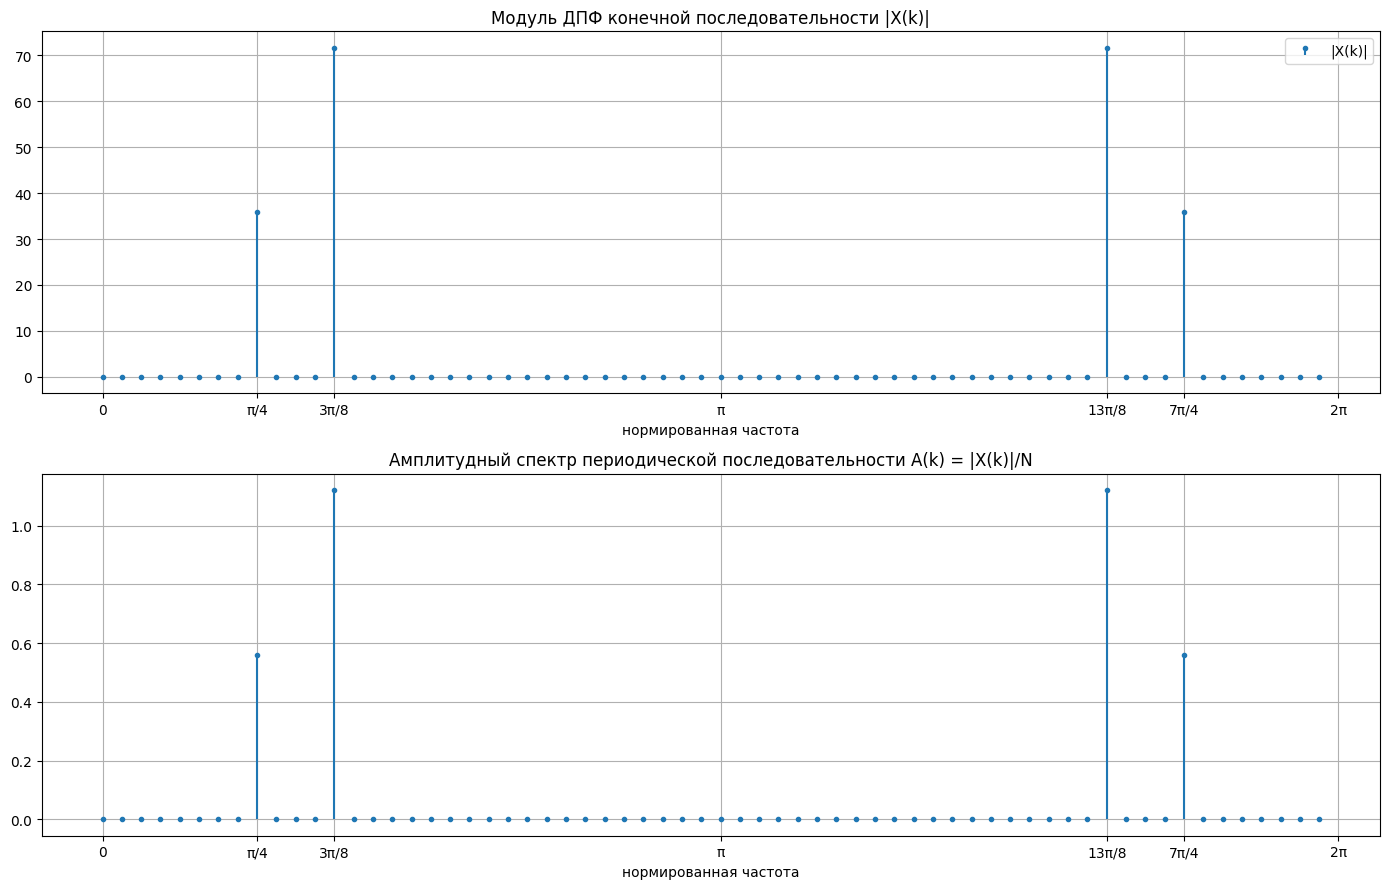

|X(8)| = 35.84  |X(12)| = 71.68


In [14]:
fig, axs = plt.subplots(2, figsize=(14, 9))
axs[0].stem(w_k, [abs(v) for v in X], basefmt=" ", markerfmt=".", label="|X(k)|")
axs[0].set_title("Модуль ДПФ конечной последовательности |X(k)|"); axs[0].legend()
axs[1].stem(w_k, Ak, basefmt=" ", markerfmt=".")
axs[1].set_title("Амплитудный спектр периодической последовательности A(k) = |X(k)|/N")
for ax in axs:
    ax.set_xticks(w_ticks, w_labels); ax.set_xlabel("нормированная частота"); ax.grid(True)
plt.tight_layout(); plt.show()

print("|X(8)| =", round(abs(X[8]), 4), " |X(12)| =", round(abs(X[12]), 4))

Поскольку ДПФ вычисляется как сумма по всем $N$ отсчётам, высота его спектральных пиков прямо пропорциональна длине выборки $N$. Чтобы получить амплитуды комплексных экспонент (коэффициенты ряда Фурье периодической последовательности), не зависящие от длины выборки, результат ДПФ делят на $N$: $A(k) = |X(k)|/N$. Для каждой гармоники это половина её амплитуды, $A_i/2$.

### п.5

Восстановление аналогового сигнала по отсчётам ДПФ на сетке $t \in [0; (N-1)T]$ с шагом $\Delta t = 0.25T$:

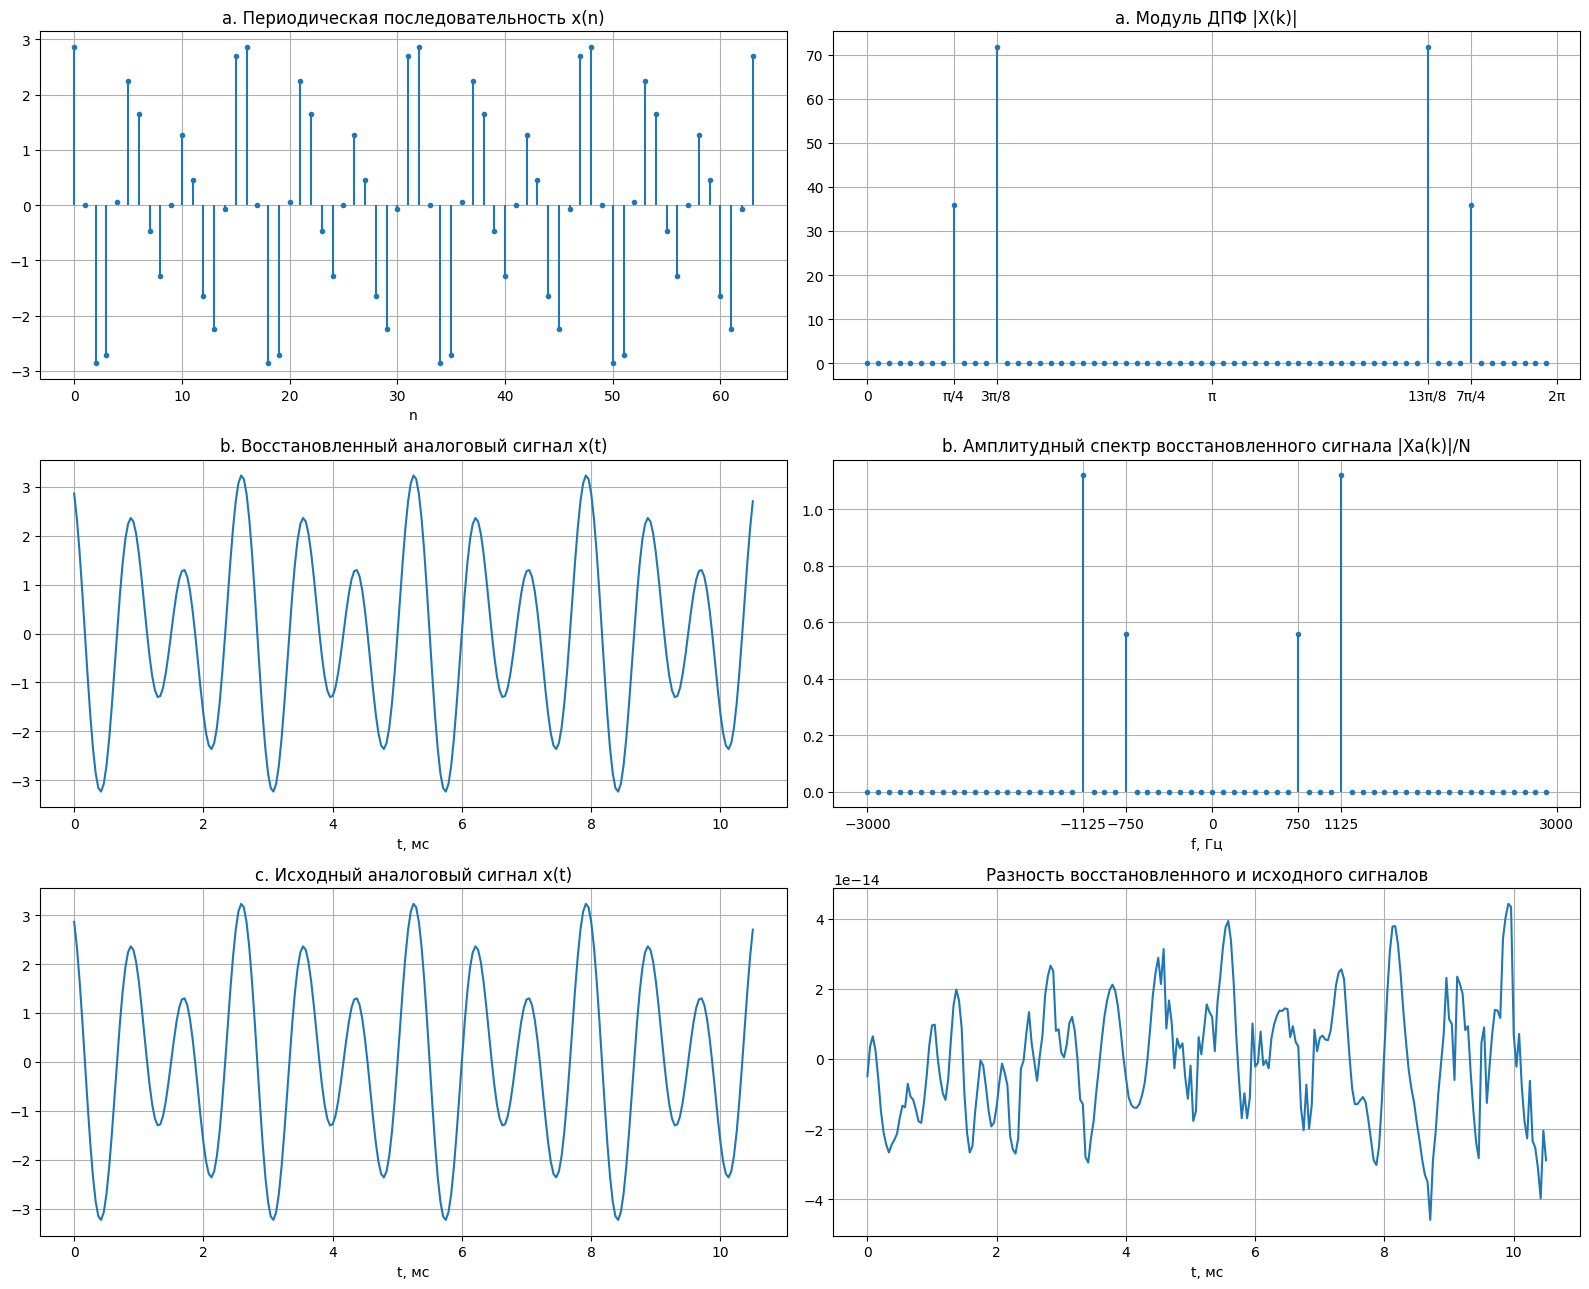

max |x_rest(t) - x(t)| = 5.6566753011182094e-14


In [15]:
def Xa(k):
    """Отсчёты ДПФ, переупорядоченные на интервал k = -N/2 ... N/2 - 1"""
    return X[k] if 0 <= k <= N//2 - 1 else X[N + k]

dt = 0.25 * T
t_list = [i * dt for i in range(4 * (N - 1) + 1)]

def restore(ts):
    x = []
    for t in ts:
        xt = 0j
        for k in range(-N//2, N//2):
            xt += Xa(k) * cmath.exp(1j * 2 * math.pi / (N * T) * k * t)
        x.append(xt / N)
    return x

x_rest   = restore(t_list)
x_analog = [calc_xa(t) for t in t_list]

k2   = list(range(-N//2, N//2))
f_k2 = [k * fs2 / N for k in k2]

fig, axs = plt.subplots(3, 2, figsize=(16, 13))
axs[0,0].stem(ns, xs, basefmt=" ", markerfmt=".");                       axs[0,0].set_title("a. Периодическая последовательность x(n)"); axs[0,0].set_xlabel("n")
axs[0,1].stem(w_k, [abs(v) for v in X], basefmt=" ", markerfmt=".");     axs[0,1].set_title("a. Модуль ДПФ |X(k)|")
axs[0,1].set_xticks(w_ticks, w_labels)
axs[1,0].plot([t*1000 for t in t_list], [v.real for v in x_rest]);       axs[1,0].set_title("b. Восстановленный аналоговый сигнал x(t)"); axs[1,0].set_xlabel("t, мс")
axs[1,1].stem(f_k2, [abs(Xa(k))/N for k in k2], basefmt=" ", markerfmt="."); axs[1,1].set_title("b. Амплитудный спектр восстановленного сигнала |Xa(k)|/N")
axs[1,1].set_xlabel("f, Гц"); axs[1,1].set_xticks([-fs2/2, -f2, -f1, 0, f1, f2, fs2/2])
axs[2,0].plot([t*1000 for t in t_list], x_analog);                       axs[2,0].set_title("c. Исходный аналоговый сигнал x(t)"); axs[2,0].set_xlabel("t, мс")
axs[2,1].plot([t*1000 for t in t_list], [x_rest[i].real - x_analog[i] for i in range(len(t_list))])
axs[2,1].set_title("Разность восстановленного и исходного сигналов"); axs[2,1].set_xlabel("t, мс")
for ax in axs.flat: ax.grid(True)
plt.tight_layout(); plt.show()

print("max |x_rest(t) - x(t)| =", max(abs(x_rest[i] - x_analog[i]) for i in range(len(t_list))))

### п.6

a. Формула восстановления — это ряд Фурье периодического аналогового сигнала с периодом $NT$:
$$
x(t) = \sum_{k=-N/2}^{N/2-1} \frac{X_a(k)}{N}\, e^{j 2\pi \frac{k}{NT} t}.
$$
Каждое слагаемое — комплексная экспонента с частотой $f_k = \frac{k}{NT} = k \frac{f_s}{N}$ и комплексной амплитудой $X_a(k)/N$. Значит, амплитудный спектр аналогового сигнала — это модуль ДПФ, делённый на $N$, а фазовый спектр — аргумент ДПФ.

Перестановка $X_a(k) = X(N+k)$ при $k < 0$ нужна потому, что вторая половина ДПФ ($k = N/2, \dots, N-1$) соответствует отрицательным частотам: из-за периодичности ДПФ $X(N+k) = X(k)$ для $k < 0$.

Каждый косинус исходного сигнала $A_i \cos(2\pi f_i t + \varphi_i)$ раскладывается на две экспоненты с частотами $\pm f_i$ и амплитудами $A_i/2$. В ДПФ им соответствуют линии при $k = \pm 8$ ($\pm 750$ Гц, $A_1/2 = 0.56$) и $k = \pm 12$ ($\pm 1125$ Гц, $A_2/2 = 1.12$). Восстановленный сигнал содержит ровно эти компоненты, поэтому его спектр совпадает со спектром исходного.

<br>

b. Восстановленный и исходный сигналы визуально неразличимы: максимальное расхождение порядка $10^{-14}$ — ошибки машинного округления. Так и должно быть: сигнал состоит ровно из четырёх комплексных экспонент, которые видны в спектре, т.е. ни одна компонента не потеряна; частоты гармоник (750 и 1125 Гц) меньше частоты Найквиста $f_s/2 = 3000$ Гц, поэтому наложения спектров нет.

### п.7

Проверка равенства Парсеваля:

In [16]:
E_time = sum(abs(v)**2 for v in xs)
E_freq = sum(abs(v)**2 for v in X) / N
print(f"E_time = {E_time:.12f}")
print(f"E_freq = {E_freq:.12f}")
print(f"error  = {E_time - E_freq:.3e}")
print(f"N*(A1^2/2 + A2^2/2) = {N * (A1**2 / 2 + A2**2 / 2):.12f}")

E_time = 200.704000000000
E_freq = 200.704000000000
error  = 2.842e-14
N*(A1^2/2 + A2^2/2) = 200.704000000000


Энергия последовательности, вычисленная во временной области, совпадает с энергией, вычисленной по отсчётам ДПФ: $E = 200.704$, расхождение порядка $10^{-14}$ (ошибки округления). Равенство Парсеваля выполняется.

Смысл равенства: ДПФ сохраняет энергию сигнала, т.е. энергию можно вычислять как во временной, так и в частотной области. Энергия распределена по спектральным составляющим: здесь вся она сосредоточена в четырёх линиях, $E = \frac{1}{N}\left(2 \cdot 35.84^2 + 2 \cdot 71.68^2\right) = N\left(\frac{A_1^2}{2} + \frac{A_2^2}{2}\right) = 64 \cdot 3.136 = 200.704$ (энергия каждой гармоники за период равна $N A^2 / 2$).

## Выводы

В работе реализовано рекурсивное звено 2-го порядка и исследованы его временные и частотные характеристики, а также выполнен спектральный анализ периодической последовательности и последовательности конечной длины с помощью ДПФ.

### Часть 1. Рекурсивное звено 2-го порядка

1. Импульсная характеристика звена вычислена по разностному уравнению и по аналитической формуле; результаты совпали с точностью до ошибок округления. Звено является БИХ-звеном: из-за обратной связи по $y(n-1)$, $y(n-2)$ длина ИХ бесконечна, а $N_1 = 22$ задаёт лишь длину вычисленного фрагмента.

2. Воздействие — прямоугольный импульс из 16 единичных отсчётов при длине последовательности $N_2 = 32$. Длина линейной свёртки 53, ненулевых отсчётов 37; свёртку ограничивают до длины воздействия, т.к. реакция вычисляется для каждого входного отсчёта, а хвост полной свёртки искажён усечением ИХ.

3. Реакции по формуле свёртки и по разностному уравнению совпадают при $n < N_1$; при $n \geqslant N_1$ свёртка даёт погрешность до $0.035$ из-за отброшенного хвоста ИХ, тогда как разностное уравнение вычисляет реакцию точно. Длина реакции по разностному уравнению равна длине воздействия, 32 отсчёта. Реакция сосредоточена на фронтах импульса в виде затухающих колебаний, а на плоской части импульса стремится к малому уровню $A(0) \approx 0.27$.

4. Нули $z_{01,2} = 1.0954\,e^{\pm j0.3162\pi}$ лежат вне единичной окружности, полюсы $z_{*1,2} = 0.8438\,e^{\pm j0.7205\pi}$ — внутри неё, поэтому звено устойчиво. Нули и полюсы образуют комплексно-сопряжённые пары, т.к. коэффициенты вещественные; карта нулей и полюсов совпадает с расчётом.

5. Вид АЧХ объясняется картой нулей и полюсов: минимум $0.061$ при $\hat{\omega} \approx 0.313\pi$ — вблизи аргумента нулей, резонансный максимум $8.82$ при $\hat{\omega} \approx 0.730\pi$ — вблизи аргумента полюсов; $A(0) \approx 0.27$, $A(\pi) \approx 3.96$. Нули не лежат на единичной окружности, поэтому АЧХ не обращается в ноль и скачка ФЧХ на $\pi$ нет; скачок на $2\pi$ при $\hat{\omega} \approx 0.46\pi$ связан только с приведением фазы к интервалу $(-\pi, \pi]$.

6. Звено является фильтром верхних частот с резонансом: низкочастотные составляющие воздействия, в которых сосредоточен спектр прямоугольного импульса, подавляются, высокие частоты усиливаются.

7. Основная полоса частот $\hat{\omega} \in [0, \pi]$ соответствует $f \in [0, f_s/2] = [0, 6000]$ Hz при $f_s = 12000$ Hz; шкалы связаны соотношением $f = \hat{\omega} f_s / (2\pi)$.

### Часть 2. ДПФ и спектральный анализ

1. Последовательность — сумма двух гармоник с частотами 750 и 1125 Hz ($\hat{\omega} = \pi/4$ и $3\pi/8$) при $f_s = 6000$ Hz, $N = 64$. На периоде $N$ укладывается ровно 8 и 12 периодов гармоник, поэтому их частоты точно попадают на отсчёты ДПФ, а последовательность периодична с периодом $N$.

2. ОДПФ от ДПФ восстанавливает исходную последовательность с погрешностью порядка $10^{-14}$, т.е. прямое и обратное ДПФ взаимно обратны.

3. Дискретное нормированное время связано с дискретным соотношением $n = nT/T$, частота в герцах с нормированной: $f_k = k f_s / N$. Амплитудный спектр содержит четыре ненулевых отсчёта $k = 8, 12, 52, 56$ с амплитудами $A_1/2 = 0.56$ и $A_2/2 = 1.12$ и фазами, равными начальным фазам гармоник: $\pm\pi/4$ и $\pm\pi/8$. Амплитудный спектр симметричен, а фазовый антисимметричен относительно $\hat{\omega} = \pi$, т.к. $X(N-k) = X^*(k)$ для вещественной последовательности.

4. Модуль ДПФ конечной последовательности отличается от амплитудного спектра периодической последовательности только множителем $N$: $A(k) = |X(k)|/N$, $|X(8)| = 35.84$, $|X(12)| = 71.68$.

5. Аналоговый сигнал, восстановленный по отсчётам ДПФ, совпадает с исходным с погрешностью порядка $10^{-14}$, т.к. частоты гармоник меньше $f_s/2 = 3000$ Hz (выполнено условие теоремы Котельникова) и в спектре нет потерянных составляющих.

6. Модуль ДПФ, делённый на $N$, с переносом второй половины ДПФ на отрицательные частоты равен амплитудному спектру аналогового сигнала: линии $0.56$ на $\pm 750$ Hz и $1.12$ на $\pm 1125$ Hz.

7. Равенство Парсеваля выполняется: энергия во временной и частотной областях равна $200.704 = N\left(A_1^2/2 + A_2^2/2\right)$, т.е. ДПФ сохраняет энергию сигнала.
